# Layer 1: one skip rate

In this notebook we fit the simplest model of the project. Every track has the same probability of being skipped, whatever the listener, the session or the last track

This model has no moods. We need it as a baseline, because the mood models must beat it to be useful.


In [ ]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from checks import (all_checks, average_log_score, load_sessions,
                    real_data_checks, split_users, to_matrix)
from posterior import predictive_table

SEED = 2026
rng = np.random.default_rng(SEED)

# Beta(1,1) gives the same weight to every skip rate before we see the data
PRIOR_A = 1
PRIOR_B = 1

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#52514e"
CONTEXT_COLOURS = {"organic": BLUE, "recommendation": ORANGE}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "axes.labelcolor": GREY,
})

## 1. The data

Each row of `sessions.csv` is one track. `skip` is 1 when the listener played 50% of the track or less.

A session has the context `recommendation` when the tracks came from a personal feed or playlist, and `organic` when the listener found them alone

In [5]:
sessions = load_sessions()

summary = sessions.groupby("context").agg(
    sessions=("session_id", "nunique"),
    tracks=("skip", "size"),
    users=("uid", "nunique"),
    skip_rate=("skip", "mean"),
)
summary["mean_length"] = summary["tracks"]/summary["sessions"]
summary

,sessions,tracks,users,skip_rate,mean_length
context,,,,,
organic,2743,41877,2743,0.444421,15.266861
recommendation,2632,41840,2632,0.390607,15.896657


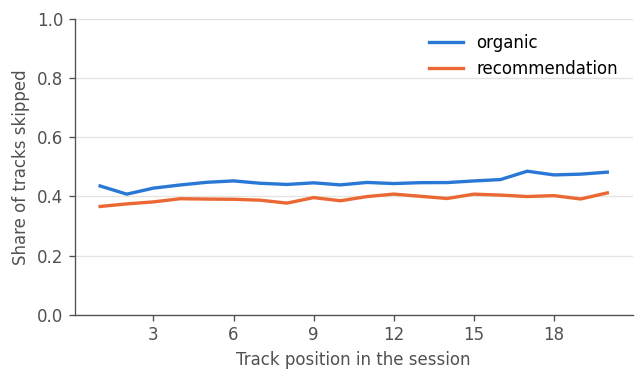

In [6]:
#the model says the skip rate is the same at every position
#this figure shows how far that is true
by_position = (sessions.groupby(["context", "position"])["skip"]
               .mean().rename("skip_rate").reset_index())

fig, ax = plt.subplots(figsize=(6, 3.2))
for context, part in by_position.groupby("context"):
    ax.plot(part["position"] + 1, part["skip_rate"], linewidth=2,
            color=CONTEXT_COLOURS[context], label=context)
ax.set_xlabel("Track position in the session")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Share of tracks skipped")
ax.set_ylim(0, 1)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.savefig("figures/layer1_skip_rate_by_position.pdf")
plt.show()

## 2. Training and test users

We keep 20% of the users for the final test. All three layers use this same split, so their scores can be compared

In [7]:
train, test =split_users(sessions, seed=SEED)

pd.concat([
    train[["uid"]].drop_duplicates().assign(group="train"),
    test[["uid"]].drop_duplicates().assign(group="test"),
]).to_csv("data/split.csv", index=False)

n_tracks =len(train)
n_skips = int(train["skip"].sum())

print(f"Training: {train['uid'].nunique()} users, {n_tracks} tracks, {n_skips} skips")
print(f"Test: {test['uid'].nunique()} users, {len(test)} tracks")

Training: 2354 users, 67122 tracks, 28088 skips
Test: 589 users, 16595 tracks


## 3. The model

For track $t$ of session $i$, $y_{it} = 1$ if the track is skipped and $y_{it} = 0$ if it is not.

$$y_{it} \mid \theta \sim \text{Bernoulli}(\theta)$$

$$\theta \sim \text{Beta}(a, b)$$

The only unknown is $\theta$, the skip rate. We use $a = b = 1$ because we want the data to decide, and every value between 0 and 1 starts with the same weight.

This is the conversion rate model of the course. A skip replaces a purchase and a track replaces a visitor. The Beta prior is conjugate, so with $s$ skips out of $n$ tracks the posterior has an exact form:

$$\theta \mid y \sim \text{Beta}(a + s,\; b + n - s)$$

So we need no sampler in this layer. The model does assume that all tracks are independent, and our checks in section 7 test this.

In [8]:
def posterior_summary(skips, tracks, a=PRIOR_A, b=PRIOR_B):
    '''Return the posterior mean and 95% interval of the skip rate'''
    a_post = a + skips
    b_post = b + tracks - skips
    return {
        "mean": a_post / (a_post + b_post),
        "low": stats.beta.ppf(0.025, a_post, b_post),
        "high": stats.beta.ppf(0.975, a_post, b_post),
    }

## 4. Validation on simulated data

We first use data where we know the true skip rate. We simulate as many tracks as in the real training data, and the true value should fall inside the 95% interval

One test can pass by luck, so we also repeat it 2000 times on small data sets. About 95% of the intervals should contain the true value

In [9]:
true_theta= 0.4
fake_skips = rng.binomial(n_tracks, true_theta)
fake_result =posterior_summary(fake_skips, n_tracks)
print(f"True value:{true_theta}")
print(f"Posterior mean: {fake_result['mean']:.4f}")
print(f"95% interval: {fake_result['low']:.4f} to {fake_result['high']:.4f}")
print(f"True value inside the interval:"
      f"{fake_result['low'] <= true_theta <= fake_result['high']}")

True value:0.4
Posterior mean: 0.3984
95% interval: 0.3947 to 0.4021
True value inside the interval:True


In [10]:
n_repeats= 2000
small_n =500
rows = []
for theta in [0.2,0.4,0.6]:
    simulated_skips = rng.binomial(small_n, theta, size=n_repeats)
    result = posterior_summary(simulated_skips, small_n)
    inside = (result["low"] <= theta) & (theta <= result["high"])
    share = inside.mean()
    rows.append({
        "true value": theta ,
        "share of intervals with the true value": share,
        "Monte Carlo standard error": np.sqrt(share * (1 - share) / n_repeats),
    })
pd.DataFrame(rows).round(4)

,true value,share of intervals with the true value,Monte Carlo standard error
0,0.2,0.9475,0.0050
1,0.4,0.9370,0.0054
2,0.6,0.9485,0.0049


## 5. Posterior of the skip rate

In [11]:
posterior = posterior_summary(n_skips, n_tracks)
a_post = PRIOR_A +n_skips
b_post = PRIOR_B + n_tracks-n_skips

print(f"Posterior: Beta({a_post}, {b_post})")
print(f"Posterior mean: {posterior['mean']:.4f}")
print(f"95% interval: {posterior['low']:.4f} to {posterior['high']:.4f}")

Posterior: Beta(28089, 39035)
Posterior mean: 0.4185
95% interval: 0.4147 to 0.4222


## 6. Do people skip more in one context?

We fit one skip rate for each context. There is no formula for the difference of two Beta variables, so we use Monte Carlo draws from each posterior

Some users appear in both contexts, and tracks in a session are probably not independent. The true uncertainty may be larger than these intervals show

In [12]:
n_draws =100_000
context_rows= []
context_draws = {}
context_rates ={}

for context, part in train.groupby("context"):
    skips_here = int(part["skip"].sum())
    tracks_here = len(part)
    result = posterior_summary(skips_here, tracks_here)
    context_rates[context] = result["mean"]
    context_draws[context] = rng.beta(PRIOR_A + skips_here,
                                      PRIOR_B + tracks_here - skips_here,
                                      size=n_draws)
    context_rows.append({"context": context, "tracks": tracks_here, **result})

pd.DataFrame(context_rows).round(4)

,context,tracks,mean,low,high
0,organic,33529,0.4453,0.4400,0.4506
1,recommendation,33593,0.3917,0.3865,0.3969


In [ ]:
difference = context_draws["recommendation"] -context_draws["organic"]
probability =(difference > 0).mean()
low, high = np.quantile(difference, [0.025, 0.975])

# A Monte Carlo share of 0 only means that no draw had this property,
# not that the probability is exactly 0, so we say it in words
if probability == 0:
    print(f"P(recommendation rate>organic rate): none of the {n_draws:,} draws")
else:
    standard_error= np.sqrt(probability * (1 - probability) / n_draws)
    print(f"P(recommendation rate>organic rate): {probability:.4f}")
    print(f"Monte Carlo standard error: {standard_error:.4f}")
print(f"Difference:mean {difference.mean():.4f}, "
      f"95% interval {low:.4f} to {high:.4f}")

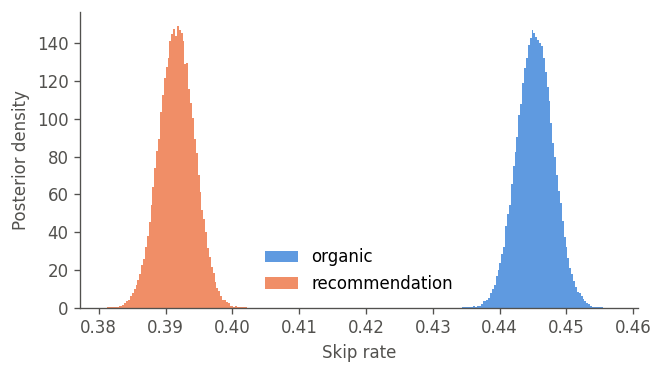

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for context, draws in context_draws.items():
    ax.hist(draws, bins=80, density=True, histtype="stepfilled",alpha=0.75,
            color=CONTEXT_COLOURS[context], label=context)
ax.set_xlabel("Skip rate")
ax.set_ylabel("Posterior density")
ax.legend(frameon=False)
fig.savefig("figures/layer1_posterior_by_context.pdf")
plt.show()

## 7. Posterior predictive checks

If the model is good, sessions simulated from it should look like the real sessions. We draw a skip rate from the posterior, simulate sessions with the same lengths as the training sessions, and repeat this 1000 times

We compare six numbers. All three layers use the same six, so they can be compared side by side:

- The spread of skip rates between sessions. It is large when some sessions have many skips and others have few.
- The gap after a skip. This is P(skip | last track skipped) minus P(skip | last track played).
- The longest run of skips, as a mean over sessions.
- The gap after shuffling. We shuffle the tracks inside each session 20 times and compute the gap after a skip again. Shuffling keeps the number of skips of each session but destroys their order, so this is the part of the gap that comes from differences between sessions.
- The within-session gap: the gap after a skip minus the gap after shuffling. This is the part that comes from the order of the tracks inside a session.
- The number of skip/play changes per session.

The real-data values use a fixed seed for the shuffles, so every layer reports the same numbers.

The last column gives the share of simulations with a value at least as large as the real one. A value very close to 0 or 1 means that the model cannot reproduce this number

In [ ]:
train_skips, train_mask =to_matrix(train)
observed_checks =pd.Series(real_data_checks(train_skips, train_mask))

n_simulations = 1000
simulated_checks =[]
for _ in range(n_simulations):
    theta = rng.beta(a_post, b_post)
    fake = (rng.random(train_skips.shape) < theta).astype(int)
    simulated_checks.append(all_checks(fake, train_mask, rng))
simulated_checks = pd.DataFrame(simulated_checks)

check_table = predictive_table(simulated_checks, observed_checks)
check_table.round(4)

In [ ]:
fig, axes =plt.subplots(2, 3, figsize=(9, 5))
for ax, name in zip(axes.ravel(), simulated_checks.columns):
    ax.hist(simulated_checks[name], bins=30, color=BLUE, label="simulated")
    ax.axvline(observed_checks[name], color=ORANGE, linewidth=2, label="real data")
    ax.set_xlabel(name.capitalize())
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_yticks([])
axes[0, 0].set_ylabel("Simulated data sets")
axes[1, 0].set_ylabel("Simulated data sets")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper center", ncol=2)
fig.subplots_adjust(hspace=0.5, wspace=0.25)
fig.savefig("figures/layer1_predictive_checks.pdf")
plt.show()

The one-rate model reproduces none of the six numbers. Tracks are independent in this model, so the spread between sessions is too small, both gaps are close to 0, and it predicts many more skip/play changes than the real sessions, because independent tracks change from skip to play very often.

## 8. Score on the test users

For each test track, the model gives the probability of what really happened. The score is the mean log probability. A higher score is better, and a fair coin gets about -0.693

This model ignores the earlier tracks, so every test track gets the posterior mean as its skip probability. We also score the version with one skip rate per context

In [17]:
test_skips, test_mask =to_matrix(test)

one_rate = np.full(test_skips.shape, posterior["mean"])
score_one_rate = average_log_score(one_rate, test_skips, test_mask)

test_rates = test["context"].map(context_rates).to_numpy()
score_by_context = np.mean(np.where(test["skip"] == 1,
                                    np.log(test_rates),
                                    np.log(1 - test_rates)))

print(f"One skip rate: {score_one_rate:.4f}")
print(f"One skip rate per context: {score_by_context:.4f}")
print(f"Fair coin: {np.log(0.5):.4f}")

One skip rate: -0.6782
One skip rate per context: -0.6767
Fair coin: -0.6931


## 9. Sensitivity to the prior

We repeat the fit with priors that expect few skips, many skips or a stronger belief around 40%. With many tracks, the prior should change almost nothing

In [18]:
priors = {"Beta(1, 1)": (1, 1), "Beta(2, 8)": (2, 8),
          "Beta(8, 2)": (8, 2), "Beta(40, 60)": (40, 60)}

pd.DataFrame([
    {"prior": name, **posterior_summary(n_skips, n_tracks, a, b)}
    for name, (a, b) in priors.items()
]).round(5)

,prior,mean,low,high
0,"Beta(1, 1)",0.41846,0.41473,0.42220
1,"Beta(2, 8)",0.41843,0.41470,0.42216
2,"Beta(8, 2)",0.41852,0.41479,0.42225
3,"Beta(40, 60)",0.41843,0.41471,0.42217


## 10. Save the results

Layers 2 and 3 read this file, so all the scores stay in one place

In [ ]:
results = {
    "posterior": {key: float(value) for key, value in posterior.items()},
    "context_rates": {key: float(value) for key, value in context_rates.items()},
    "probability_recommendation_higher": float(probability),
    "observed_checks": observed_checks.to_dict(),
    "predictive_checks": check_table.to_dict(orient="index"),
    "score_one_rate": float(score_one_rate),
    "score_by_context": float(score_by_context),
}
with open("results/layer1.json", "w") as file:
    json.dump(results, file, indent=2)
print(json.dumps(results, indent=2))